## Part 1

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs('output', exist_ok=True)

## Step A — Industry Sector Selection and Data Filtering

### A.1 Choose the industry sector

In [2]:
major_groups = pd.read_csv('data/major_groups.csv')
major_groups.head()

,major_group,description
0,1,Agricultural Production Crops
1,2,Agriculture production livestock and animal sp...
2,7,Agricultural Services
3,8,Forestry
4,9,Fishing hunting and trapping


In [3]:
# our chosen sector: Business Services
sector = 73
major_groups[major_groups['major_group'] == sector]

,major_group,description
61,73,Business Services


### A.2 Filter `public_firms.csv` to the selected sector


In [4]:
firms = pd.read_csv('data/public_firms.csv')
print(firms.shape)
firms.head()

(247890, 12)


,gvkey,fyear,conm,cik,ipodate,sic,asset,cash,net_income,sale,prcc_c,location
0,1004,1994,AAR CORP,1750.0,1972-04-24,5080,425.814,22.487,10.463,451.395,13.374999,USA
1,1004,1995,AAR CORP,1750.0,1972-04-24,5080,437.846,33.606,16.012,504.990,21.999998,USA
2,1004,1996,AAR CORP,1750.0,1972-04-24,5080,529.584,51.705,23.025,589.328,30.249985,USA
3,1004,1997,AAR CORP,1750.0,1972-04-24,5080,670.559,17.222,35.657,782.123,38.749992,USA
4,1004,1998,AAR CORP,1750.0,1972-04-24,5080,726.630,8.250,41.671,918.036,23.875000,USA


In [5]:
# keep only firms whose SIC code starts with 73
bs = firms[firms['sic'] // 100 == sector]
print(bs.shape)
bs.head()

(30610, 12)


,gvkey,fyear,conm,cik,ipodate,sic,asset,cash,net_income,sale,prcc_c,location
52,1019,1994,AFA PROTECTIVE SYSTEMS INC,2668.0,NaN,7380,26.742,6.447,1.503,25.755,NaN,USA
53,1019,1995,AFA PROTECTIVE SYSTEMS INC,2668.0,NaN,7380,28.487,4.565,1.339,27.492,115.0,USA
54,1019,1996,AFA PROTECTIVE SYSTEMS INC,2668.0,NaN,7380,28.968,5.293,1.060,27.160,117.0,USA
55,1019,1997,AFA PROTECTIVE SYSTEMS INC,2668.0,NaN,7380,26.710,1.654,1.139,29.740,215.0,USA
56,1019,1998,AFA PROTECTIVE SYSTEMS INC,2668.0,NaN,7380,29.283,1.507,1.647,34.175,207.0,USA


In [6]:
# which SIC codes make up the sector
bs['sic'].value_counts().head(10)

sic
7370    10377
7372     9701
7373     2849
7389     1811
7374     1237
7363      803
7359      640
7310      639
7371      502
7311      354
Name: count, dtype: int64

### A.3 Questions on the filtered dataset

**a. How many unique firm-year observations are there?**

In [7]:
n_firm_years = bs[['gvkey', 'fyear']].drop_duplicates().shape[0]   # not from class: drop_duplicates
print('Rows in filtered data          :', bs.shape[0])
print('Unique firm-year observations  :', n_firm_years)
print('Distinct fiscal years covered  :', len(bs['fyear'].unique()), f"({bs['fyear'].min()}-{bs['fyear'].max()})")

Rows in filtered data          : 30610
Unique firm-year observations  : 30610
Distinct fiscal years covered  : 32 (1994-2025)


**b. How many unique firms are there?** 

In [8]:
n_firms = len(bs['gvkey'].unique())

print('Unique firms (gvkey):', n_firms)

Unique firms (gvkey): 3273


**c. How many firms have records in all 32 years (1994–2025)?**

In [9]:
years_per_firm = bs['gvkey'].value_counts()


full_history = years_per_firm[years_per_firm == 32]
print('Firms with all 32 years of records:', len(full_history))

Firms with all 32 years of records: 64


In [10]:

pd.set_option('display.max_rows', 100)   

rows_2025 = bs[bs['fyear'] == 2025]
full_ids = list(full_history.index)     


keep = []
for firm in rows_2025['gvkey']:
    keep.append(firm in full_ids)

full_firms = rows_2025[keep]
full_firms = full_firms[['conm', 'sic', 'location', 'sale']].sort_values('sale', ascending=False)
full_firms.columns = ['Firm', 'SIC', 'Location', 'Sales 2025 (USD m)']
full_firms.index = range(1, len(full_firms) + 1)   # number the firms 1, 2, 3 ...
full_firms

# Name, version, company of Al tool: Opus 5.5, Claude AI
# Chat objective: Fix Error
# Use of Al-generated content: Provided us with code with explanation of steps and reasoning
# Time and date of chat: 3rd October

,Firm,SIC,Location,Sales 2025 (USD m)
1,MICROSOFT CORP,7372,USA,281724.000
2,INTL BUSINESS MACHINES CORP,7370,USA,67535.000
3,ORACLE CORP,7372,USA,67357.000
4,ADOBE INC,7370,USA,23769.000
5,FUJITSU LTD,7373,JPN,22031.060
6,FISERV INC,7389,USA,21193.000
7,AUTOMATIC DATA PROCESSING,7374,USA,20560.900
8,INTUIT INC,7372,USA,18831.000
9,WPP PLC,7311,GBR,18236.945
10,MANPOWERGROUP,7363,USA,17957.100


## Step B — Preliminary Analysis

### B.1 Top 10 firms by stock price (`prcc_c`) in 2020 and 2025

In [11]:
bs_2020 = bs[bs['fyear'] == 2020]
top_price_2020 = bs_2020.sort_values('prcc_c', ascending=False)[['conm', 'sic', 'prcc_c']].head(10)
top_price_2020

# Name, version, company of Al tool: Opus 5.5, Claude AI
# Chat objective: Fix Error
# Use of Al-generated content: Provided us with code with explanation of steps and reasoning
# Time and date of chat: 3rd October

,conm,sic,prcc_c
213155,ALPHABET INC,7370,1752.64
223284,CONSTELLATION SOFTWARE INC,7370,1303.04
88895,SHOPIFY INC,7370,1131.95
182520,COSTAR GROUP INC,7370,924.28
105041,TRADE DESK INC,7370,801.00
222619,SERVICENOW INC,7372,550.43
57718,FAIR ISAAC CORP,7373,511.04
50774,ADOBE INC,7370,500.12
79706,PAYCOM SOFTWARE INC,7370,452.25
42516,TYLER TECHNOLOGIES INC,7373,436.52


In [12]:
bs_2025 = bs[bs['fyear'] == 2025]
top_price_2025 = bs_2025.sort_values('prcc_c', ascending=False)[['conm', 'sic', 'prcc_c']].head(10)
top_price_2025

,conm,sic,prcc_c
223289,CONSTELLATION SOFTWARE INC,7370,2399.743
57723,FAIR ISAAC CORP,7373,1690.620
172492,UNITED RENTALS INC,7350,809.320
136812,APPLOVIN CORP,7311,673.820
105385,INTUIT INC,7372,662.420
222074,META PLATFORMS INC,7370,660.090
129013,SPOTIFY TECHNOLOGY SA,7370,580.710
212978,MASTERCARD INC,7389,570.880
7177,CACI INTL INC -CL A,7373,532.810
26815,S&P GLOBAL INC,7323,522.590


### B.2 Top 10 firms by sales (sale) over the entire history


In [13]:

bs_sales = bs.dropna(subset=['sale'])                                
best_year_idx = bs_sales.groupby('gvkey')['sale'].idxmax()
top_sales = bs.loc[best_year_idx, ['conm', 'fyear', 'sale']].sort_values('sale', ascending=False).head(10)
top_sales.columns = ['conm', 'peak_year', 'peak_sale_musd']
top_sales

# Name, version, company of Al tool: Opus 5.5, Claude AI
# Chat objective: Write Code for us
# Use of Al-generated content: Provided us with code from the given data and explain the steps
# Time and date of chat: 3rd October

,conm,peak_year,peak_sale_musd
213160,ALPHABET INC,2025,402836.000
48616,MICROSOFT CORP,2025,281724.000
222074,META PLATFORMS INC,2025,200966.000
21959,INTL BUSINESS MACHINES CORP,2011,106916.000
48648,ORACLE CORP,2025,67357.000
74388,FUJITSU LTD,2010,54717.315
29061,NEC CORP,1999,48460.650
177159,SAP SE,2025,43207.817
212174,SALESFORCE INC,2025,41525.000
153481,LUCENT TECHNOLOGIES INC,1999,38303.000


In [14]:

bs.sort_values('sale', ascending=False)[['conm', 'fyear', 'sale']].head(10)

,conm,fyear,sale
213160,ALPHABET INC,2025,402836.0
213159,ALPHABET INC,2024,350018.0
213158,ALPHABET INC,2023,307394.0
213157,ALPHABET INC,2022,282836.0
48616,MICROSOFT CORP,2025,281724.0
213156,ALPHABET INC,2021,257637.0
48615,MICROSOFT CORP,2024,245122.0
48614,MICROSOFT CORP,2023,211915.0
222074,META PLATFORMS INC,2025,200966.0
48613,MICROSOFT CORP,2022,198270.0


### B.3 Geographical distribution (location) — top 10 locations

In [15]:

print('Firms with >1 location:', (bs.groupby('gvkey')['location'].nunique() > 1).sum())

# Name, version, company of Al tool: Opus 5.5, Claude AI
# Chat objective: Write Code for us
# Use of Al-generated content: Provided us with code from the given data and explain the steps
# Time and date of chat: 3rd October

Firms with >1 location: 0


In [16]:
firm_level = bs.drop_duplicates('gvkey')          
location_counts = firm_level['location'].value_counts()
print('Number of locations:', len(location_counts))
top10_locations = location_counts.head(10)
top10_locations

# Name, version, company of Al tool: Opus 5.5, Claude AI
# Chat objective: Fix Error
# Use of Al-generated content: Provided us with code with explanation of steps and reasoning
# Time and date of chat: 3rd October

Number of locations: 46


location
USA    2684
CHN     152
CAN      80
ISR      76
GBR      56
HKG      39
SGP      33
JPN      22
IRL      15
NLD      11
Name: count, dtype: int64

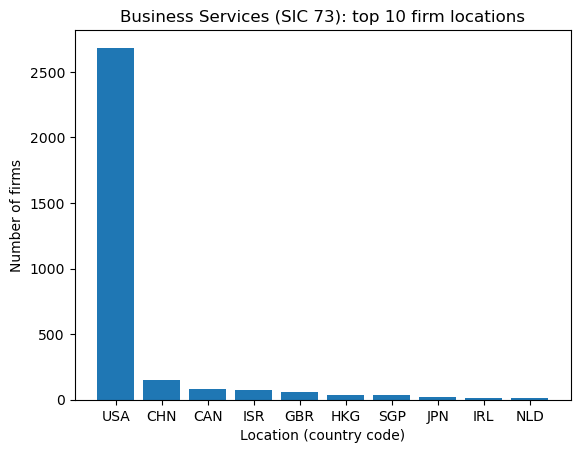

In [17]:
plt.bar(top10_locations.index, top10_locations.values)
plt.xlabel('Location (country code)')
plt.ylabel('Number of firms')
plt.title('Business Services (SIC 73): top 10 firm locations')
plt.savefig('output/B3_top10_locations.png', dpi=200, bbox_inches='tight')
plt.show()

### B.4 Average stock price across the years

In [18]:
avg_price = bs.groupby('fyear')['prcc_c'].mean()
avg_price.round(2)

fyear
1994    12.61
1995    15.87
1996    14.43
1997    14.50
1998    15.50
1999    28.04
2000    10.56
2001     9.35
2002     7.01
2003    11.08
2004    12.41
2005    12.91
2006    14.74
2007    15.59
2008     9.47
2009    14.94
2010    17.30
2011    15.33
2012    17.36
2013    25.06
2014    22.61
2015    23.78
2016    25.27
2017    32.98
2018    35.91
2019    41.96
2020    60.94
2021    54.81
2022    32.03
2023    44.03
2024    51.85
2025    47.77
Name: prcc_c, dtype: float64

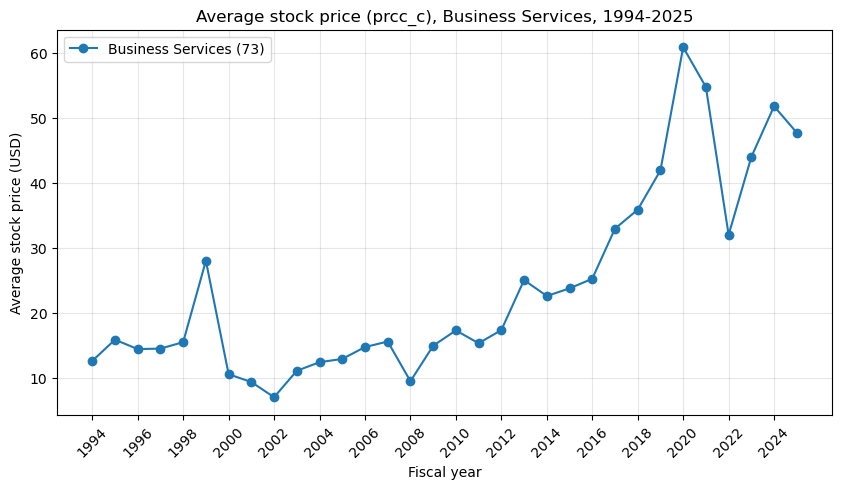

In [19]:
plt.figure(figsize=(10, 5))
plt.plot(avg_price.index, avg_price.values, marker='o', label='Business Services (73)')
plt.xlabel('Fiscal year')
plt.ylabel('Average stock price (USD)')
plt.title('Average stock price (prcc_c), Business Services, 1994-2025')
plt.xticks(range(1994, 2026, 2), rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.savefig('output/B4_avg_stock_price.png', dpi=200, bbox_inches='tight')
plt.show()

### B.5 Firm most affected by the 2008 Financial Crisis

In [20]:
p2007 = bs[bs['fyear'] == 2007][['gvkey', 'conm', 'prcc_c']]
p2008 = bs[bs['fyear'] == 2008][['gvkey', 'prcc_c']]


crisis = p2007.merge(p2008, on='gvkey', suffixes=('_2007', '_2008'))    
crisis = crisis.dropna()
crisis = crisis[crisis['prcc_c_2007'] > 0]

crisis['pct_change'] = (crisis['prcc_c_2008'] - crisis['prcc_c_2007']) / crisis['prcc_c_2007'] * 100
print('Firms compared:', crisis.shape[0])
crisis.sort_values('pct_change').head(10).round(4)

# Name, version, company of Al tool: Opus 5.5, Claude AI
# Chat objective: Fix Error
# Use of Al-generated content: Provided us with code with explanation of steps and reasoning
# Time and date of chat: 3rd October

Firms compared: 666


,gvkey,conm,prcc_c_2007,prcc_c_2008,pct_change
699,183139,ACCESS NEWSWIRE INC,1.250,0.0071,-99.4320
585,165442,DEBT RESOLVE INC,1.040,0.0110,-98.9423
292,64319,MEDIALINK WORLDWIDE INC,4.250,0.0551,-98.7035
225,61836,BLACK TITAN CORP,1.680,0.0220,-98.6905
454,133425,ARTISTDIRECT INC,0.380,0.0050,-98.6842
507,146738,APPLIED DIGITAL CORP,1.850,0.0250,-98.6486
353,112005,FARMHOUSE INC,0.720,0.0100,-98.6111
156,25830,DATASCENSION INC,0.630,0.0100,-98.4127
613,176066,NEXTWAVE WIRELESS INC,5.380,0.0900,-98.3271
336,105132,CREATOR CAPITAL LTD,0.045,0.0010,-97.7778


In [21]:
most_hit = crisis.loc[crisis['pct_change'].idxmin()]
print(f"Most affected firm: {most_hit['conm']}  "
      f"(${most_hit['prcc_c_2007']:.2f} -> ${most_hit['prcc_c_2008']:.4f}, {most_hit['pct_change']:.2f}%)")

# Name, version, company of Al tool: Opus 5.5, Claude AI
# Chat objective: Write Code for us
# Use of Al-generated content: Provided us with code from the given data
# Time and date of chat: 3rd October

Most affected firm: ACCESS NEWSWIRE INC  ($1.25 -> $0.0071, -99.43%)


In [22]:
crisis_5 = crisis[crisis['prcc_c_2007'] >= 5]
print('Firms with 2007 price >= $5:', crisis_5.shape[0])
crisis_5.sort_values('pct_change').head(10).round(2)

Firms with 2007 price >= $5: 394


,gvkey,conm,prcc_c_2007,prcc_c_2008,pct_change
613,176066,NEXTWAVE WIRELESS INC,5.38,0.09,-98.33
509,147262,MEDICAL STAFFNG NTWRK HLDGS,6.03,0.24,-96.10
540,160336,PLANETOUT INC,6.21,0.36,-94.20
658,178494,REMARK HOLDINGS INC,6.23,0.38,-93.90
430,125358,NAVISITE INC,5.06,0.40,-92.09
495,143668,MAGMA DESIGN AUTOMATION INC,12.21,1.02,-91.65
626,176782,GLU MOBILE INC,5.22,0.50,-90.42
293,64325,BLUEPHOENIX SOLUTIONS LTD,18.12,1.84,-89.85
628,176900,XINHUA SPORTS & ENTMT LTD,6.00,0.62,-89.67
141,25021,VALASSIS COMMUNICATIONS INC,11.69,1.32,-88.71


In [23]:

print('Median % change in stock price, 2007->2008:', round(crisis['pct_change'].median(), 2))

Median % change in stock price, 2007->2008: -52.86


### B.6 Average Return on Assets (ROA) for USA firms


In [24]:
usa = bs[bs['location'] == 'USA'].copy()
usa = usa[usa['asset'] > 0]
usa['roa'] = usa['net_income'] / usa['asset']
usa = usa.dropna(subset=['roa'])
print(usa.shape)
usa['roa'].describe()

(23686, 13)


count    23686.000000
mean        -2.339482
std         43.322683
min      -3495.000000
25%         -0.322682
50%         -0.028205
75%          0.054395
max        683.200000
Name: roa, dtype: float64

In [25]:
avg_roa = usa.groupby('fyear')['roa'].mean()
median_roa = usa.groupby('fyear')['roa'].median()
roa_table = pd.DataFrame({'mean_roa': avg_roa, 'median_roa': median_roa, 'n_firms': usa.groupby('fyear')['roa'].count()})
roa_table.round(3)

,mean_roa,median_roa,n_firms
fyear,,,
1994,-0.186,0.032,683
1995,-0.170,0.023,891
1996,-0.214,0.011,967
1997,0.011,-0.017,1030
1998,-0.726,-0.096,1245
1999,-0.493,-0.105,1262
2000,-0.978,-0.188,1155
2001,-3.890,-0.231,1033
2002,-6.221,-0.120,958


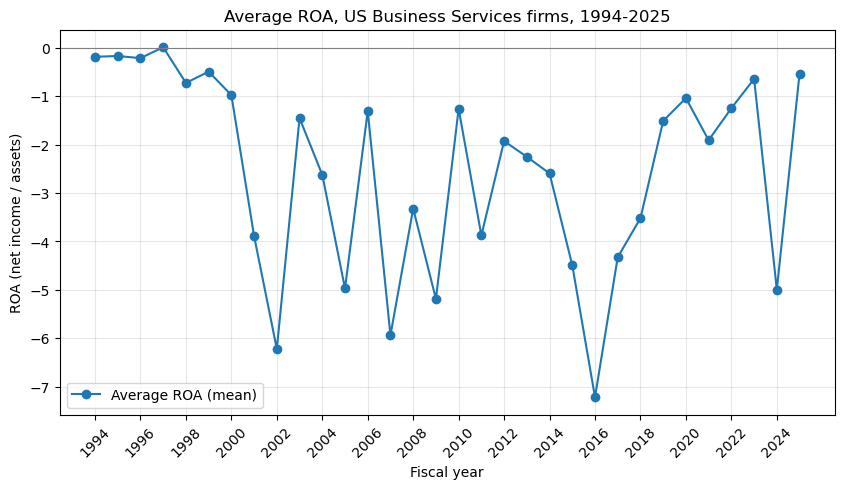

In [30]:
plt.figure(figsize=(10, 5))
plt.plot(avg_roa.index, avg_roa.values, marker='o', label='Average ROA (mean)')
plt.axhline(0, color='grey', linewidth=0.8)
plt.xlabel('Fiscal year')
plt.ylabel('ROA (net income / assets)')
plt.title('Average ROA, US Business Services firms, 1994-2025')
plt.xticks(range(1994, 2026, 2), rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.savefig('output/B6_avg_roa_usa.png', dpi=200, bbox_inches='tight')
plt.show()

# Name, version, company of Al tool: Opus 5.5, Claude AI
# Chat objective: Write Code for us
# Use of Al-generated content: Provided us with code from the given data and explain the steps
# Time and date of chat: 3rd October

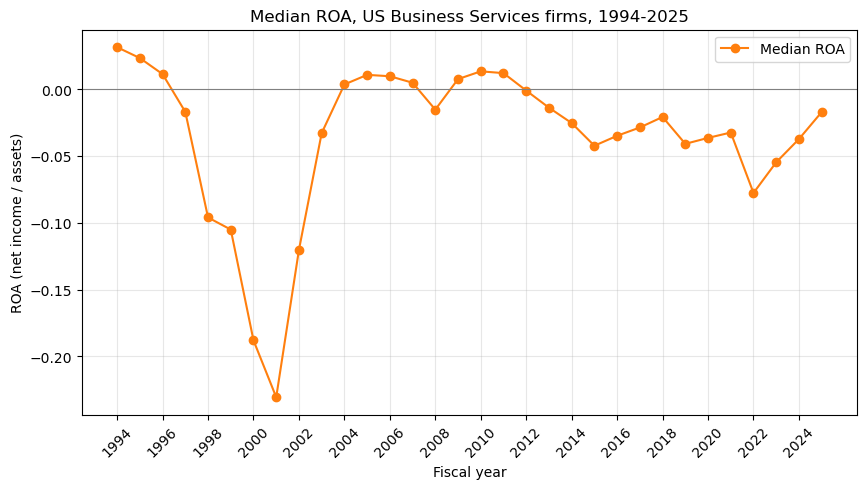

In [27]:
plt.figure(figsize=(10, 5))
plt.plot(median_roa.index, median_roa.values, marker='o', color='tab:orange', label='Median ROA')
plt.axhline(0, color='grey', linewidth=0.8)
plt.xlabel('Fiscal year')
plt.ylabel('ROA (net income / assets)')
plt.title('Median ROA, US Business Services firms, 1994-2025')
plt.xticks(range(1994, 2026, 2), rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.savefig('output/B6_median_roa_usa.png', dpi=200, bbox_inches='tight')
plt.show()

# Name, version, company of Al tool: Opus 5.5, Claude AI
# Chat objective: Fix Error
# Use of Al-generated content: Provided us with code with explanation of steps and reasoning
# Time and date of chat: 3rd October